# 09 — Comparative Analysis

**Single place to compare every model in the zoo from its saved `results/*.json`.**

Each model notebook (01–08) and the subject-independent driver (notebook 10) write a
`results/<Model>_results.json` file with the LOSO headline metrics, the cross-fold
mean ± std, per-fold scores and a confusion matrix. This notebook only *reads* those
files — it trains nothing — and produces the comparison table plus the figures:

1. Headline metrics table (accuracy / F1 / precision / recall ± std, params, train time)
2. Grouped bar chart of the four metrics per model
3. Accuracy per model with chance + majority-baseline reference lines
4. Per-held-out-subject accuracy heatmap
5. Accuracy vs parameter count (efficiency frontier)
6. Accuracy vs training time
7. Per-fold accuracy spread (box + strip) per model
8. Confusion-matrix grid (row-normalised) for every model
9. Radar chart of the normalised metric profile

Figures are also written to `results/figures/` and the table to
`results/comparative_analysis.csv`.

## 1. Setup

In [1]:
import os, sys, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
RESULTS_DIR = os.path.join(ROOT, "results")
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.axisbelow": True, "font.size": 10})
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

BASELINE = "MajorityBaseline"
METRICS = ["accuracy", "precision", "recall", "f1"]
print("results dir :", RESULTS_DIR)
print("json files  :", [os.path.basename(p) for p in sorted(glob.glob(f"{RESULTS_DIR}/*_results.json"))])

results dir : /Users/maheshsinghmadai/Documents/Repos/EEG-based-Emotion-Recognition-using-Deep-Learning/eeg-emotion-benchmark/results
json files  : ['CIT_EmotionNet_results.json', 'CNN_Transformer_Reduced_results.json', 'DADPc_results.json', 'DGCNN_results.json', 'DualAttention_TransformerCNNBiLSTM_results.json', 'EEGNet_results.json', 'MajorityBaseline_results.json', 'SiamGCAN_results.json']


## 2. Load every `results/*.json`

`PROTOCOL` selects which block to read from each file (`loso` is the only one the
current runs write). Anything that fails to parse or lacks that block is skipped
with a warning rather than killing the notebook.

In [2]:
PROTOCOL = "loso"          # block key inside each results file

def load_results(results_dir=RESULTS_DIR, protocol=PROTOCOL):
    records = []
    for path in sorted(glob.glob(os.path.join(results_dir, "*_results.json"))):
        try:
            blob = json.load(open(path))
        except Exception as exc:                       # noqa: BLE001
            print(f"[skip] {os.path.basename(path)}: unreadable ({exc!r})")
            continue
        block = blob.get(protocol)
        if not block:
            print(f"[skip] {os.path.basename(path)}: no '{protocol}' block")
            continue
        folds = block.get("per_fold_scores", []) or []
        records.append({
            "model":          blob.get("model", os.path.basename(path).split("_results")[0]),
            "family":         blob.get("family", "-"),
            "label":          blob.get("config", {}).get("label", "-"),
            "feature":        blob.get("config", {}).get("feature", "-"),
            "quick":          bool(blob.get("config", {}).get("quick", False)),
            "params":         block.get("params_count") or np.nan,
            "train_time_sec": block.get("train_time_sec") or np.nan,
            "n_folds":        len(folds),
            "accuracy":       block.get("accuracy", np.nan),
            "precision":      block.get("precision", np.nan),
            "recall":         block.get("recall", np.nan),
            "f1":             block.get("f1", np.nan),
            "accuracy_std":   block.get("accuracy_std", np.nan),
            "precision_std":  block.get("precision_std", np.nan),
            "recall_std":     block.get("recall_std", np.nan),
            "f1_std":         block.get("f1_std", np.nan),
            "confusion_matrix": np.array(block.get("confusion_matrix", []), dtype=float),
            "fold_acc":       [f.get("accuracy", np.nan) for f in folds],
            "fold_f1":        [f.get("f1", np.nan) for f in folds],
            "fold_subject":   [f.get("test_subject", f"fold_{f.get('fold', i)}")
                               for i, f in enumerate(folds)],
        })
    return records

records = load_results()
print(f"\nloaded {len(records)} models:", [r["model"] for r in records])

# split model rows from the baseline, sort models by accuracy
model_rows = sorted([r for r in records if r["model"] != BASELINE],
                    key=lambda r: r["accuracy"], reverse=True)
baseline   = next((r for r in records if r["model"] == BASELINE), None)
ordered    = model_rows + ([baseline] if baseline else [])
MODEL_ORDER = [r["model"] for r in ordered]


loaded 8 models: ['CIT_EmotionNet', 'CNN_Transformer_Reduced', 'DADPc', 'DGCNN', 'DualAttention_TransformerCNNBiLSTM', 'EEGNet', 'MajorityBaseline', 'SiamGCAN']


## 3. Headline metrics table

In [3]:
def pm(m, s):
    if m is None or (isinstance(m, float) and np.isnan(m)):
        return "-"
    return f"{m:.3f} ± {s:.3f}" if not (isinstance(s, float) and np.isnan(s)) else f"{m:.3f}"

table = pd.DataFrame([{
    "Model":     r["model"],
    "Family":    r["family"],
    "Feature":   r["feature"],
    "Folds":     r["n_folds"],
    "Params":    f"{int(r['params']):,}" if not np.isnan(r["params"]) else "-",
    "Accuracy":  pm(r["accuracy"],  r["accuracy_std"]),
    "F1":        pm(r["f1"],        r["f1_std"]),
    "Precision": pm(r["precision"], r["precision_std"]),
    "Recall":    pm(r["recall"],    r["recall_std"]),
    "Fold acc range": (f"{np.nanmin(r['fold_acc']):.2f}–{np.nanmax(r['fold_acc']):.2f}"
                       if r["fold_acc"] else "-"),
    "Train (s)": f"{r['train_time_sec']:,.0f}" if not np.isnan(r["train_time_sec"]) else "-",
    "Quick?":    "yes" if r["quick"] else "no",
} for r in ordered])

# numeric frame for plotting / csv
num = pd.DataFrame([{
    "model": r["model"], "family": r["family"], "params": r["params"],
    "train_time_sec": r["train_time_sec"], "n_folds": r["n_folds"],
    **{m: r[m] for m in METRICS},
    **{f"{m}_std": r[f"{m}_std"] for m in METRICS},
} for r in ordered]).set_index("model")

csv_path = os.path.join(RESULTS_DIR, "comparative_analysis.csv")
num.to_csv(csv_path)
print("wrote", csv_path)
if any(r["quick"] for r in ordered):
    print("⚠️  some rows are from a QUICK smoke run (few folds / few epochs)\n")
table

wrote /Users/maheshsinghmadai/Documents/Repos/EEG-based-Emotion-Recognition-using-Deep-Learning/eeg-emotion-benchmark/results/comparative_analysis.csv
⚠️  some rows are from a QUICK smoke run (few folds / few epochs)



,Model,Family,Feature,Folds,Params,Accuracy,F1,Precision,Recall,Fold acc range,Train (s),Quick?
0,DGCNN,Graph CNN,de,2,"67,030",0.706 ± 0.018,0.671 ± 0.017,0.686 ± 0.007,0.668 ± 0.023,0.69–0.72,5,yes
1,DADPc,Domain adaptation,de,3,"34,628",0.680 ± 0.023,0.652 ± 0.014,0.675 ± 0.011,0.656 ± 0.018,0.66–0.71,21,yes
2,CIT_EmotionNet,CNN-Transformer,de,2,"220,610",0.658 ± 0.026,0.591 ± 0.080,0.612 ± 0.084,0.597 ± 0.077,0.63–0.68,21,yes
3,DualAttention_TransformerCNNBiLSTM,CNN-BiLSTM-Transformer,raw,2,"309,339",0.616 ± 0.016,0.529 ± 0.066,0.542 ± 0.055,0.544 ± 0.051,0.60–0.63,98,yes
4,CNN_Transformer_Reduced,CNN-Transformer (5ch),raw,2,"185,859",0.603 ± 0.030,0.502 ± 0.009,0.572 ± 0.042,0.536 ± 0.016,0.57–0.63,57,yes
5,SiamGCAN,Graph CNN + Siamese,de,23,"46,922",0.584 ± 0.089,0.490 ± 0.104,0.484 ± 0.133,0.534 ± 0.072,0.39–0.79,"2,767",no
6,EEGNet,CNN,raw,3,"1,842",0.560 ± 0.077,0.368 ± 0.038,0.377 ± 0.074,0.490 ± 0.007,0.50–0.67,45,yes
7,MajorityBaseline,baseline,-,3,-,0.573 ± 0.076,0.363 ± 0.030,0.287 ± 0.038,0.500 ± 0.000,0.51–0.68,1,yes


## 4. Grouped bar chart — the four metrics per model

Error bars are the cross-fold std reported in each results file.

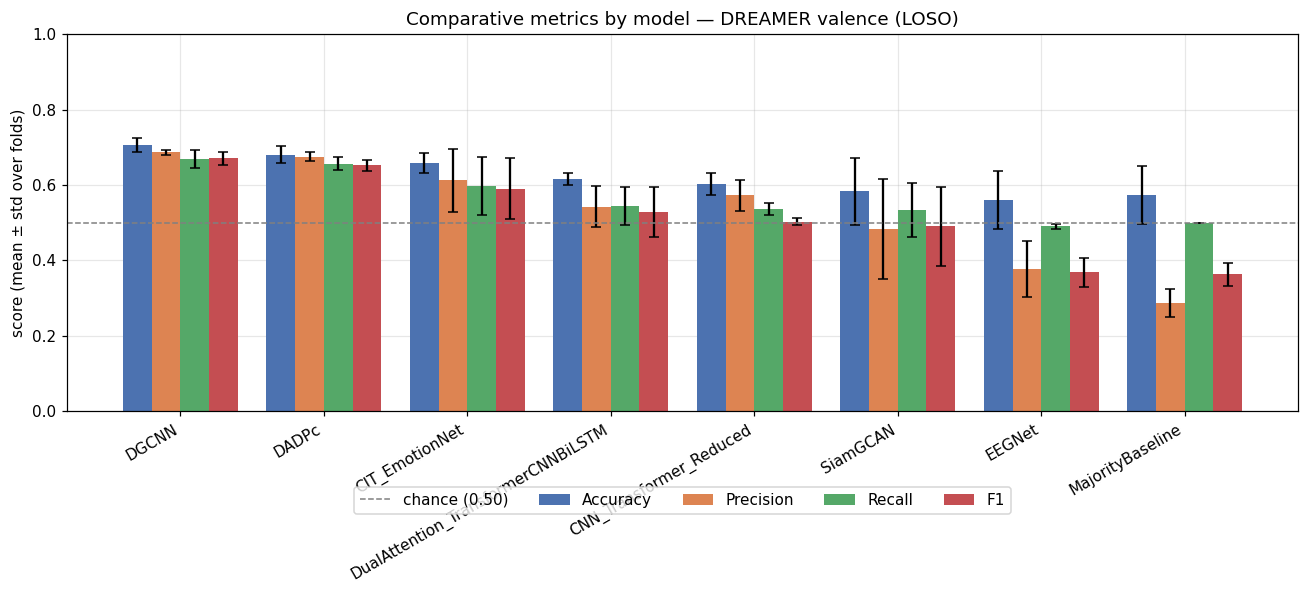

In [4]:
plot_models = [r for r in ordered]
names = [r["model"] for r in plot_models]
x = np.arange(len(names))
w = 0.2
colors = {"accuracy": "#4C72B0", "precision": "#DD8452", "recall": "#55A868", "f1": "#C44E52"}

fig, ax = plt.subplots(figsize=(max(9, 1.5 * len(names)), 5.5))
for k, m in enumerate(METRICS):
    vals = [r[m] for r in plot_models]
    errs = [r[f"{m}_std"] for r in plot_models]
    ax.bar(x + (k - 1.5) * w, vals, w, yerr=errs, capsize=3, label=m.capitalize(),
           color=colors[m])
ax.axhline(0.5, ls="--", lw=1, color="grey", label="chance (0.50)")
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_ylabel("score (mean ± std over folds)")
ax.set_ylim(0, 1)
ax.set_title(f"Comparative metrics by model — DREAMER {ordered[0]['label']} ({PROTOCOL.upper()})")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ca_metrics_by_model.png"), bbox_inches="tight")
plt.show()

## 5. Accuracy per model with reference lines

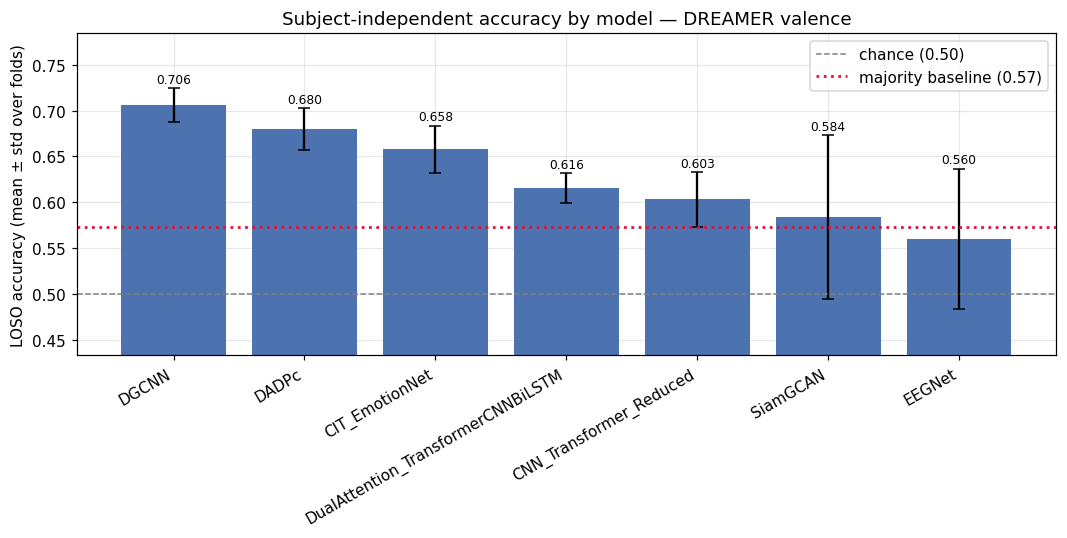

In [5]:
fig, ax = plt.subplots(figsize=(max(8, 1.4 * len(model_rows)), 5))
xm = np.arange(len(model_rows))
bars = ax.bar(xm, [r["accuracy"] for r in model_rows],
              yerr=[r["accuracy_std"] for r in model_rows], capsize=4, color="#4C72B0")
ax.axhline(0.5, ls="--", lw=1, color="grey", label="chance (0.50)")
if baseline:
    ax.axhline(baseline["accuracy"], ls=":", lw=1.8, color="crimson",
               label=f"majority baseline ({baseline['accuracy']:.2f})")
for xi, r in zip(xm, model_rows):
    ax.text(xi, r["accuracy"] + r["accuracy_std"] + 0.006, f"{r['accuracy']:.3f}",
            ha="center", fontsize=8)
ax.set_xticks(xm)
ax.set_xticklabels([r["model"] for r in model_rows], rotation=30, ha="right")
ax.set_ylabel("LOSO accuracy (mean ± std over folds)")
lo = min([r["accuracy"] - r["accuracy_std"] for r in model_rows] + [0.5]) - 0.05
hi = max([r["accuracy"] + r["accuracy_std"] for r in model_rows]) + 0.06
ax.set_ylim(max(0, lo), min(1, hi))
ax.set_title(f"Subject-independent accuracy by model — DREAMER {ordered[0]['label']}")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ca_accuracy_by_model.png"), bbox_inches="tight")
plt.show()

## 6. Per-held-out-subject accuracy heatmap

One column per LOSO fold (held-out subject). Empty cells mean that model was run
with fewer folds (e.g. a QUICK smoke test).

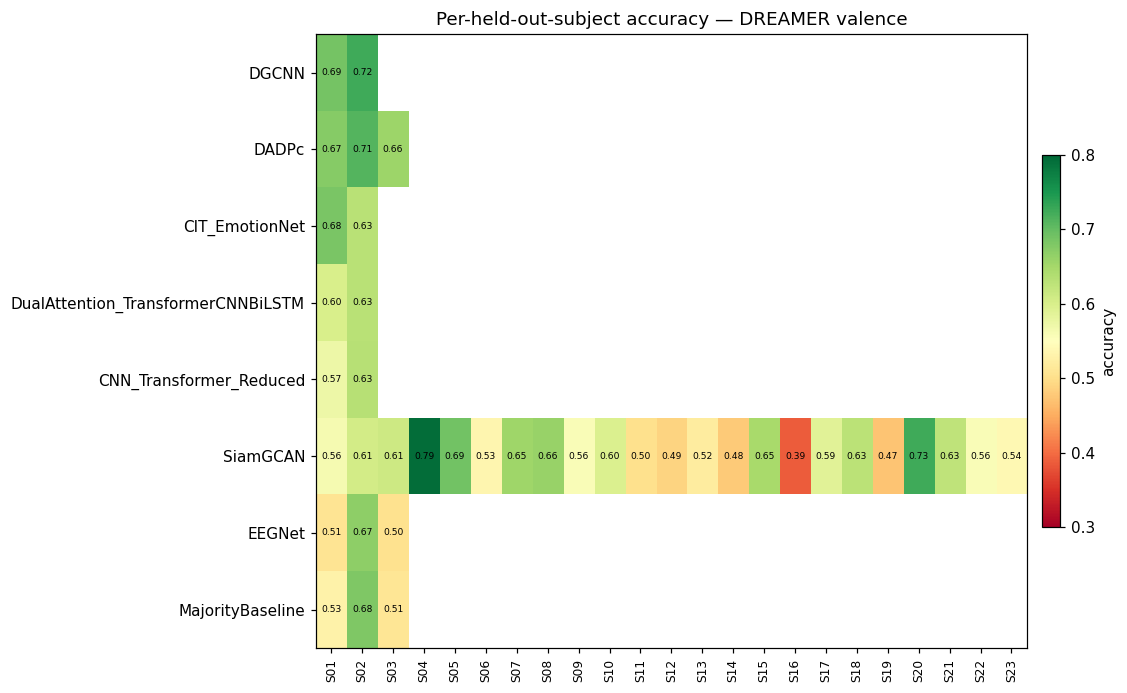

In [6]:
subj_axis = sorted({s for r in ordered for s in r["fold_subject"]},
                   key=lambda s: (len(s), s))
M = np.full((len(ordered), len(subj_axis)), np.nan)
for i, r in enumerate(ordered):
    for subj, acc in zip(r["fold_subject"], r["fold_acc"]):
        if subj in subj_axis:
            M[i, subj_axis.index(subj)] = acc

fig, ax = plt.subplots(figsize=(max(8, 0.45 * len(subj_axis)), 0.55 * len(ordered) + 2))
im = ax.imshow(M, cmap="RdYlGn", vmin=0.3, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(subj_axis)))
ax.set_xticklabels([s.replace("subject_", "S") for s in subj_axis], rotation=90, fontsize=8)
ax.set_yticks(range(len(ordered)))
ax.set_yticklabels([r["model"] for r in ordered])
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if not np.isnan(M[i, j]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, label="accuracy", fraction=0.025, pad=0.02)
ax.set_title(f"Per-held-out-subject accuracy — DREAMER {ordered[0]['label']}")
ax.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ca_per_subject_heatmap.png"), bbox_inches="tight")
plt.show()

## 7. Accuracy vs efficiency

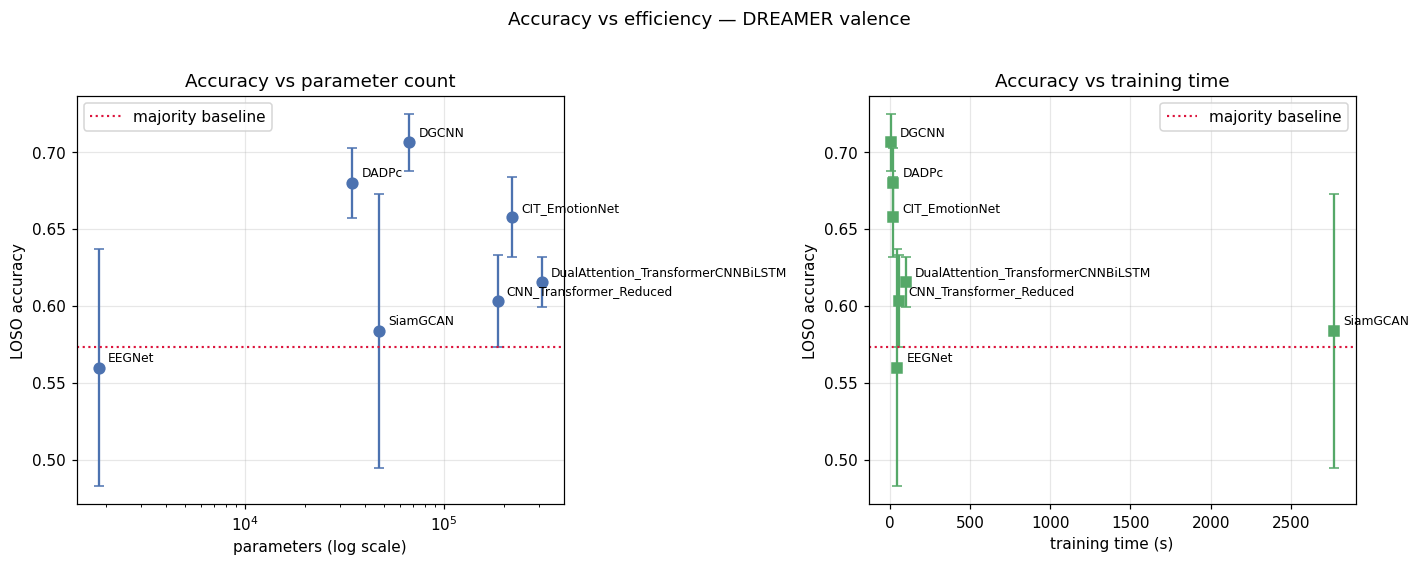

In [7]:
eff = [r for r in model_rows if not np.isnan(r["params"])]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 7a. accuracy vs parameter count
ax = axes[0]
if eff:
    ax.errorbar([r["params"] for r in eff], [r["accuracy"] for r in eff],
                yerr=[r["accuracy_std"] for r in eff], fmt="o", ms=7, capsize=3, color="#4C72B0")
    for r in eff:
        ax.annotate(r["model"], (r["params"], r["accuracy"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.set_xscale("log")
if baseline:
    ax.axhline(baseline["accuracy"], ls=":", color="crimson", lw=1.4, label="majority baseline")
    ax.legend()
ax.set_xlabel("parameters (log scale)")
ax.set_ylabel("LOSO accuracy")
ax.set_title("Accuracy vs parameter count")

# 7b. accuracy vs training time
ax = axes[1]
tt = [r for r in model_rows if not np.isnan(r["train_time_sec"])]
if tt:
    ax.errorbar([r["train_time_sec"] for r in tt], [r["accuracy"] for r in tt],
                yerr=[r["accuracy_std"] for r in tt], fmt="s", ms=7, capsize=3, color="#55A868")
    for r in tt:
        ax.annotate(r["model"], (r["train_time_sec"], r["accuracy"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=8)
if baseline:
    ax.axhline(baseline["accuracy"], ls=":", color="crimson", lw=1.4, label="majority baseline")
    ax.legend()
ax.set_xlabel("training time (s)")
ax.set_ylabel("LOSO accuracy")
ax.set_title("Accuracy vs training time")

plt.suptitle(f"Accuracy vs efficiency — DREAMER {ordered[0]['label']}", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ca_accuracy_vs_efficiency.png"), bbox_inches="tight")
plt.show()

## 8. Per-fold accuracy spread

Box = interquartile range across folds, points = individual held-out subjects.
Wide spread ⇒ the model is unstable across subjects.

/var/folders/3t/g7q5d0s17zs9t841zq1sgfjh0000gn/T/ipykernel_6116/2483586581.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, showmeans=True, patch_artist=True)


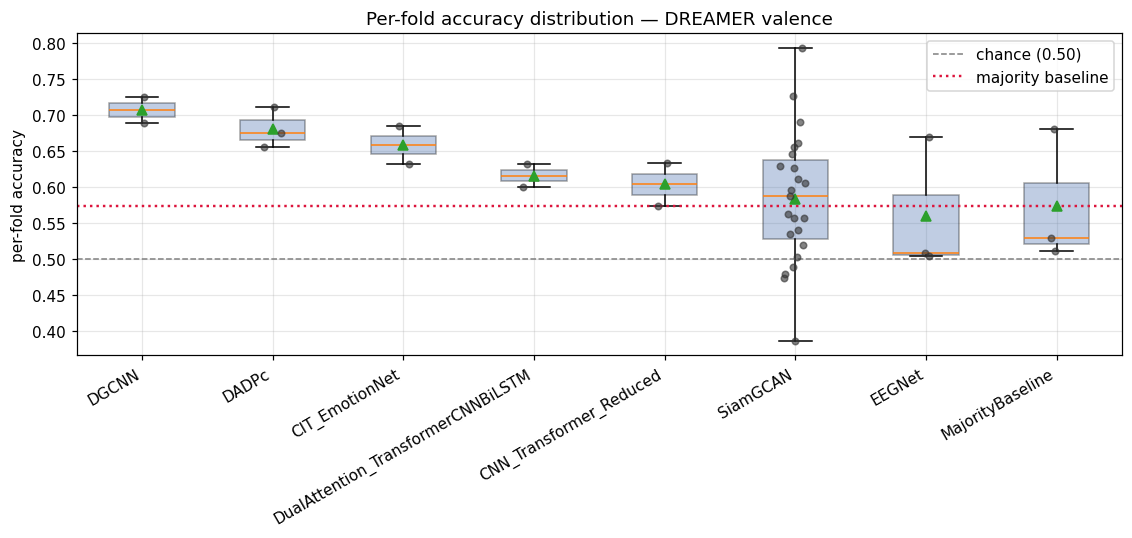

In [8]:
spread = [r for r in ordered if r["fold_acc"]]
data = [np.array(r["fold_acc"], dtype=float) for r in spread]
labels = [r["model"] for r in spread]

fig, ax = plt.subplots(figsize=(max(8, 1.3 * len(spread)), 5))
bp = ax.boxplot(data, labels=labels, showmeans=True, patch_artist=True)
for patch in bp["boxes"]:
    patch.set(facecolor="#4C72B0", alpha=0.35)
for i, d in enumerate(data, start=1):
    ax.scatter(np.random.normal(i, 0.05, size=len(d)), d, s=18, color="#333", alpha=0.6, zorder=3)
ax.axhline(0.5, ls="--", lw=1, color="grey", label="chance (0.50)")
if baseline:
    ax.axhline(baseline["accuracy"], ls=":", lw=1.6, color="crimson", label="majority baseline")
ax.set_ylabel("per-fold accuracy")
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_title(f"Per-fold accuracy distribution — DREAMER {ordered[0]['label']}")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ca_fold_accuracy_spread.png"), bbox_inches="tight")
plt.show()

## 9. Confusion-matrix grid (row-normalised)

Aggregated confusion matrix from each results file, normalised per true class so the
diagonal reads as per-class recall.

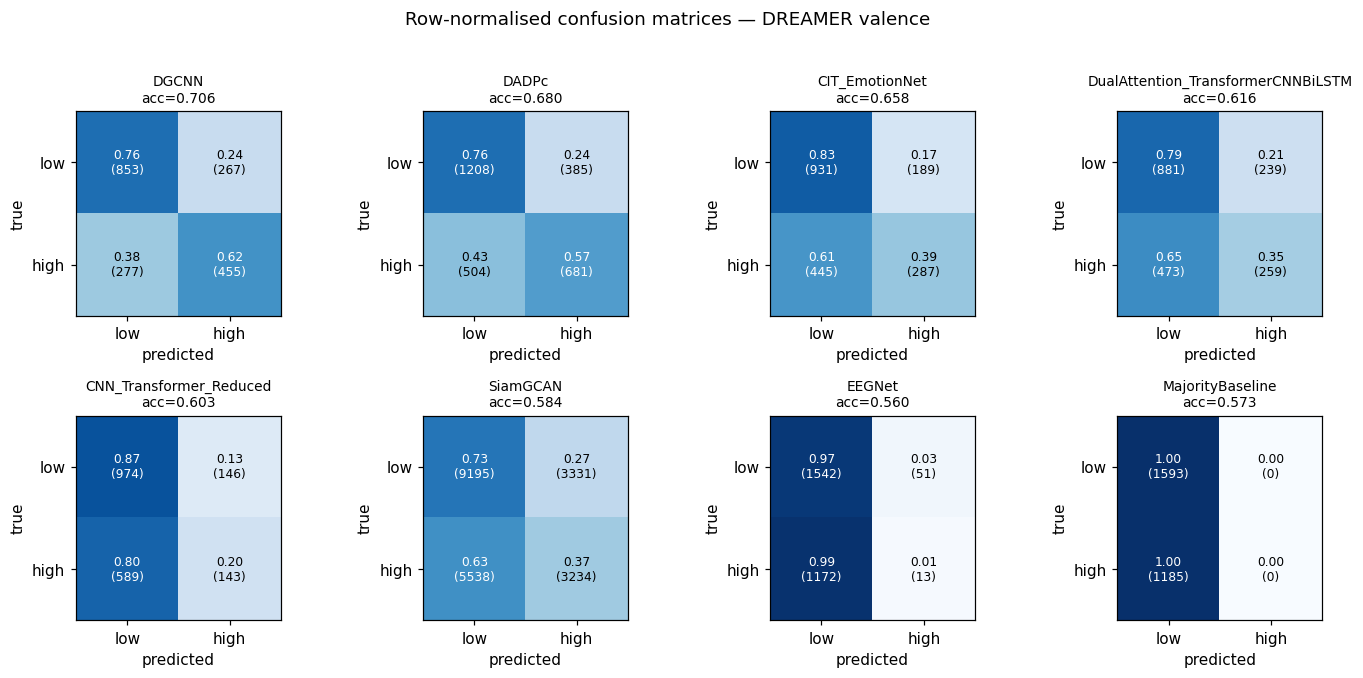

In [9]:
cm_rows = [r for r in ordered if r["confusion_matrix"].size]
ncol = min(4, len(cm_rows))
nrow = int(np.ceil(len(cm_rows) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.0 * nrow))
axes = np.atleast_1d(axes).ravel()

CLASSES = ["low", "high"]        # binary valence/arousal; adjust if labels change
for ax, r in zip(axes, cm_rows):
    cm = r["confusion_matrix"]
    norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    k = cm.shape[0]
    ax.set_xticks(range(k)); ax.set_yticks(range(k))
    ax.set_xticklabels(CLASSES[:k]); ax.set_yticklabels(CLASSES[:k])
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(k):
        for j in range(k):
            ax.text(j, i, f"{norm[i, j]:.2f}\n({int(cm[i, j])})", ha="center", va="center",
                    fontsize=8, color="white" if norm[i, j] > 0.5 else "black")
    ax.set_title(f"{r['model']}\nacc={r['accuracy']:.3f}", fontsize=9)
    ax.grid(False)
for ax in axes[len(cm_rows):]:
    ax.axis("off")
plt.suptitle(f"Row-normalised confusion matrices — DREAMER {ordered[0]['label']}", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ca_confusion_grid.png"), bbox_inches="tight")
plt.show()

## 10. Radar chart — normalised metric profile

Each metric is min–max scaled across models so the shape shows *relative* strengths
(a model that dominates every axis fills the chart). The baseline is included for
reference.

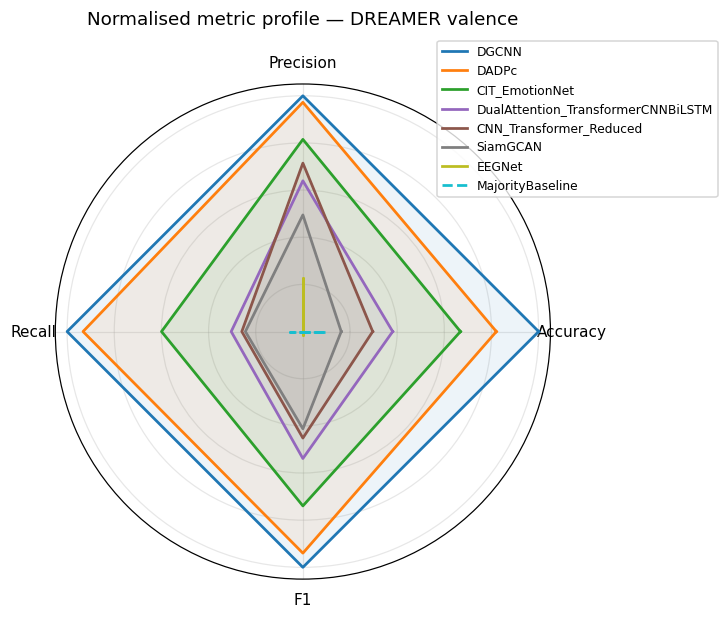

In [10]:
radar_rows = ordered
prof = np.array([[r[m] for m in METRICS] for r in radar_rows], dtype=float)
lo, hi = np.nanmin(prof, axis=0), np.nanmax(prof, axis=0)
scaled = (prof - lo) / np.clip(hi - lo, 1e-9, None)

angles = np.linspace(0, 2 * np.pi, len(METRICS), endpoint=False)
angles = np.concatenate([angles, angles[:1]])

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
cmap = plt.cm.tab10(np.linspace(0, 1, len(radar_rows)))
for r, row, c in zip(radar_rows, scaled, cmap):
    vals = np.concatenate([row, row[:1]])
    style = "--" if r["model"] == BASELINE else "-"
    ax.plot(angles, vals, style, lw=1.8, color=c, label=r["model"])
    ax.fill(angles, vals, color=c, alpha=0.08)
ax.set_xticks(angles[:-1])
ax.set_xticklabels([m.capitalize() for m in METRICS])
ax.set_yticklabels([])
ax.set_title(f"Normalised metric profile — DREAMER {ordered[0]['label']}", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ca_radar_profile.png"), bbox_inches="tight")
plt.show()

## 11. Takeaways

```python
best = model_rows[0]
```

* **Best subject-independent accuracy:** the top row of the table in §3.
* **Best accuracy-per-parameter:** check §7a — a small model near the top-left is the
  efficiency winner.
* **Most stable across subjects:** the narrowest box in §8.
* Every figure is saved under `results/figures/ca_*.png`; the numeric table is
  `results/comparative_analysis.csv`.

In [11]:
best = model_rows[0]
print(f"Top model              : {best['model']}  "
      f"(acc {best['accuracy']:.3f} ± {best['accuracy_std']:.3f}, f1 {best['f1']:.3f})")
if baseline:
    print(f"Majority baseline acc  : {baseline['accuracy']:.3f}")
    print(f"Lift over baseline     : {best['accuracy'] - baseline['accuracy']:+.3f}")
eff_sorted = sorted([r for r in model_rows if not np.isnan(r['params'])],
                    key=lambda r: r['accuracy'] / np.log10(r['params']), reverse=True)
if eff_sorted:
    print(f"Best acc / log10(params): {eff_sorted[0]['model']}")
stable = min([r for r in model_rows if r['fold_acc']],
             key=lambda r: np.nanstd(r['fold_acc']))
print(f"Most stable across folds: {stable['model']}  (fold-acc std {np.nanstd(stable['fold_acc']):.3f})")
print(f"\nFigures written to      : {FIG_DIR}")

Top model              : DGCNN  (acc 0.706 ± 0.018, f1 0.671)
Majority baseline acc  : 0.573
Lift over baseline     : +0.133
Best acc / log10(params): EEGNet
Most stable across folds: DualAttention_TransformerCNNBiLSTM  (fold-acc std 0.016)

Figures written to      : /Users/maheshsinghmadai/Documents/Repos/EEG-based-Emotion-Recognition-using-Deep-Learning/eeg-emotion-benchmark/results/figures
